# The Useful Hour
### One unit of cost for a three-generation estate — Challenge 03, *Beyond the Mainframe*

**The question:** how might an organisation see what its computing actually costs, when the estate
spans generations of systems that each account for cost differently?

**Our answer:** stop comparing *billed* hours and compare **useful** hours. A billed vCPU-hour on a
machine that is 20% busy buys a fifth of an hour of work. Divide cost by the work actually done and
mainframe, distributed and cloud finally share one unit — built only from columns the data lake
already holds.

**What it changes**

| | |
|---|---|
| **The price gap** | Mainframe looks **7.2×** dearer than cloud per billed vCPU-hour, but only **2.2×** per useful one. |
| **The migration case** | A unit-price comparison promises an **86%** saving from leaving the mainframe. Counting the cloud estate's real utilisation, it is **54%** — and it flips to a loss if one mainframe hour needs more than **~2.2** cloud vCPU-hours to replace. |
| **Money on the table today** | **£1.2M a year** from idle, over-provisioned and weekend non-production workloads on cloud and distributed — **without moving anything** — plus £1.2M of idle mainframe capacity to reclaim (section 4). |
| **Nobody's money** | The single largest "business unit" in the estate is **UNALLOCATED** — and ownership cannot be inferred from technical metadata (we tried; section 5). |

So *"should we leave the mainframe?"* is the wrong question. The right one is **"what does a useful
hour cost, wherever it runs — and who owns it?"**

> **Data caveat.** Every number here comes from the challenge's **synthetic** FinOps estate (CC0,
> seeded generator in this repo). Carbon uses **synthetic** grid intensity and is a method
> demonstration, never a measured result. No client data was used.

## 0 · Setup

In [1]:
import json, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

CHALLENGE = "c03-beyond-the-mainframe"

def find_gold() -> str:
    # Prefer a local build (python build/build.py build --challenge c03-beyond-the-mainframe
    # --version v1 --out sample/data/c03-beyond-the-mainframe); fall back to the published,
    # immutable v1 release so results are reproducible against the judged tag.
    here = pathlib.Path.cwd().resolve()
    for p in [here, *here.parents]:
        cand = p / "sample" / "data" / CHALLENGE / "gold"
        if cand.exists():
            return str(cand)
    return f"https://data.inno-forum.co.uk/{CHALLENGE}/v1/gold"

GOLD = find_gold()
OUT = pathlib.Path("outputs"); OUT.mkdir(exist_ok=True)

cost   = pd.read_parquet(f"{GOLD}/workload_cost_daily.parquet")
carbon = pd.read_parquet(f"{GOLD}/carbon_by_workload.parquet")
cb     = pd.read_parquet(f"{GOLD}/chargeback_allocation.parquet")
cost["usage_date"] = pd.to_datetime(cost["usage_date"])
carbon["usage_date"] = pd.to_datetime(carbon["usage_date"])

# One palette for every chart, taken from the event's own brand greens.
PLAT = ["mainframe", "distributed", "cloud"]
COL = {"mainframe": "#0d3b2c", "distributed": "#8a8a84", "cloud": "#35c46f"}
ACCENT = "#eb6834"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})

gbp = lambda x: f"£{x/1e6:,.2f}M" if abs(x) >= 1e6 else f"£{x/1e3:,.0f}k"
TOTAL = cost.cost_gbp.sum()
print("source :", GOLD)
print({n: f"{len(d):,} rows" for n, d in [("workload_cost_daily", cost), ("carbon_by_workload", carbon), ("chargeback_allocation", cb)]})
print("window :", cost.usage_date.min().date(), "→", cost.usage_date.max().date(), f"({cost.usage_date.nunique()} days)")
print("spend  :", gbp(TOTAL), "a year across", f"{cost.workload_id.nunique():,}", "workloads")

source : /home/user/hackathon-data/sample/data/c03-beyond-the-mainframe/gold
{'workload_cost_daily': '419,750 rows', 'carbon_by_workload': '419,750 rows', 'chargeback_allocation': '8,136 rows'}
window : 2025-10-01 → 2026-09-30 (365 days)
spend  : £15.33M a year across 1,150 workloads


## 1 · Can we trust the numbers? (Integration)

Before any finding: the grain is what the catalogue says, the cost↔carbon join is one-to-one on a
real key, and chargeback reconciles to the source to the penny. A FinOps view that does not tie back
to source is the most common real-world defect, so we check it first rather than assume it.

In [2]:
key = ["workload_id", "usage_date"]
assert not cost.duplicated(key).any(), "duplicate workload-days"
assert len(cost) == cost.workload_id.nunique() * cost.usage_date.nunique(), "gaps in the grid"

joined = cost.merge(carbon[key + ["business_unit", "platform", "energy_kwh", "carbon_kg"]],
                    on=key, how="outer", suffixes=("", "_c"), indicator=True, validate="one_to_one")
print("cost ↔ carbon join :", joined["_merge"].value_counts().to_dict())
print("attribute agreement:",
      "business_unit", bool((joined.business_unit == joined.business_unit_c).all()), "|",
      "platform", bool((joined.platform == joined.platform_c).all()))

recon = cost.cost_gbp.sum() - cb.allocated_cost_gbp.sum()
print(f"chargeback reconciles to source within £{abs(recon):,.2f} "
      f"({cost.cost_gbp.sum():,.2f} vs {cb.allocated_cost_gbp.sum():,.2f})")
assert abs(recon) < 1.0
est = joined.drop(columns=["_merge", "business_unit_c", "platform_c"])

cost ↔ carbon join : {'both': 419750, 'left_only': 0, 'right_only': 0}
attribute agreement: business_unit True | platform True
chargeback reconciles to source within £0.00 (15,325,232.68 vs 15,325,232.68)


## 2 · One unit for three generations

Each platform reports cost its own way — MIPS-equivalent hours, VM hours, cloud instance hours. All
three, in this lake, share two columns: **billed vCPU-hours** and **utilisation**. Cost in this
estate does not fall when utilisation falls: an idle hour is billed like a busy one. So:

$$\text{useful vCPU-hours} = \text{vCPU-hours} \times \frac{\text{utilisation \%}}{100}
\qquad\qquad
\textbf{£ per useful hour} = \frac{\text{cost}}{\text{useful vCPU-hours}}$$

It is deliberately simple: anyone in IT, finance or the boardroom can recompute it, and it needs no
data the lake does not already hold.

In [3]:
est["useful_vcpu_hours"] = est.vcpu_hours * est.utilisation_pct / 100

unit = (est.groupby("platform")
          .agg(workloads=("workload_id", "nunique"), cost_gbp=("cost_gbp", "sum"),
               billed_hrs=("vcpu_hours", "sum"), useful_hrs=("useful_vcpu_hours", "sum"))
          .reindex(PLAT))
unit["share_of_spend"]   = unit.cost_gbp / TOTAL
unit["utilisation"]      = unit.useful_hrs / unit.billed_hrs          # hours-weighted
unit["gbp_per_billed"]   = unit.cost_gbp / unit.billed_hrs
unit["gbp_per_useful"]   = unit.cost_gbp / unit.useful_hrs
unit["billed_vs_cloud"]  = unit.gbp_per_billed / unit.loc["cloud", "gbp_per_billed"]
unit["useful_vs_cloud"]  = unit.gbp_per_useful / unit.loc["cloud", "gbp_per_useful"]

unit.style.format({"workloads": "{:,}", "cost_gbp": "£{:,.0f}", "billed_hrs": "{:,.0f}",
                   "useful_hrs": "{:,.0f}", "share_of_spend": "{:.1%}", "utilisation": "{:.1%}",
                   "gbp_per_billed": "£{:.3f}", "gbp_per_useful": "£{:.3f}",
                   "billed_vs_cloud": "{:.1f}×", "useful_vs_cloud": "{:.1f}×"})

,workloads,cost_gbp,billed_hrs,useful_hrs,share_of_spend,utilisation,gbp_per_billed,gbp_per_useful,billed_vs_cloud,useful_vs_cloud
platform,,,,,,,,,,
mainframe,347,"£13,150,116","26,661,616","18,969,006",85.8%,71.1%,£0.493,£0.693,7.2×,2.2×
distributed,346,"£1,112,106","12,261,818","4,469,229",7.3%,36.4%,£0.091,£0.249,1.3×,0.8×
cloud,457,"£1,063,011","15,593,038","3,333,760",6.9%,21.4%,£0.068,£0.319,1.0×,1.0×


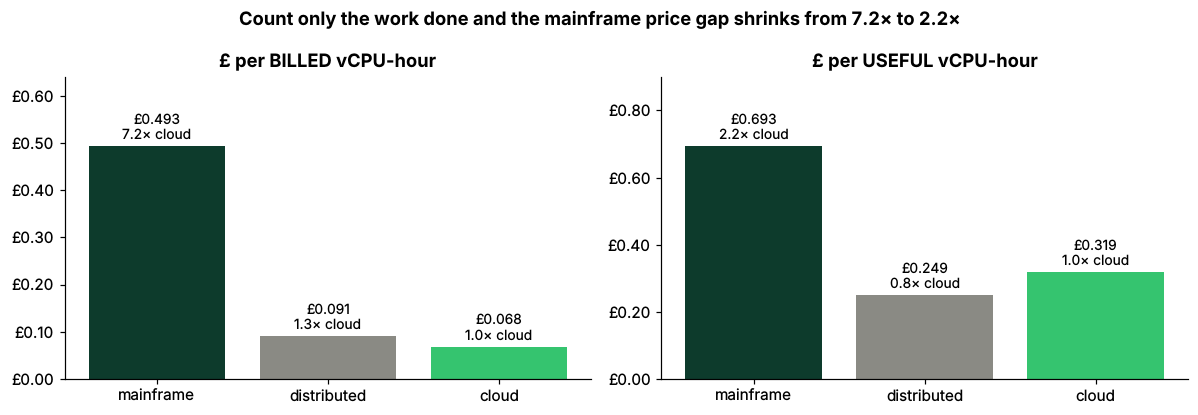

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
x = np.arange(len(PLAT))
for a, col, title in [(ax[0], "gbp_per_billed", "£ per BILLED vCPU-hour"),
                      (ax[1], "gbp_per_useful", "£ per USEFUL vCPU-hour")]:
    bars = a.bar(x, unit[col], color=[COL[p] for p in PLAT])
    a.set_xticks(x, PLAT); a.set_title(title)
    a.yaxis.set_major_formatter(mtick.StrMethodFormatter("£{x:.2f}"))
    for b, v, r in zip(bars, unit[col], unit[col] / unit.loc["cloud", col]):
        a.annotate(f"£{v:.3f}\n{r:.1f}× cloud", (b.get_x() + b.get_width()/2, v),
                   ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
    a.set_ylim(0, unit[col].max() * 1.3)
fig.suptitle("Count only the work done and the mainframe price gap shrinks from "
             f"{unit.loc['mainframe','billed_vs_cloud']:.1f}× to {unit.loc['mainframe','useful_vs_cloud']:.1f}×",
             fontweight="bold")
plt.tight_layout(); plt.savefig(OUT / "fig_unit_cost.png", bbox_inches="tight"); plt.show()

**What to notice.** Per billed hour the mainframe is the expensive outlier. Per useful hour the gap
closes by more than two thirds, and **distributed — not cloud — is the cheapest place to do a unit of
work**, because the cloud estate pays for roughly four idle hours for every busy one. The headline
"mainframe is 7× dearer" is mostly a statement about *cloud utilisation*, not about the mainframe.

## 3 · The migration exchange rate

A migration business case quietly assumes two numbers nobody in this estate measures:

1. **The exchange rate** — how many cloud vCPU-hours replace one mainframe (MIPS-equivalent) hour of
   useful work. The data labels mainframe compute as *MIPS-equivalent*, so 1 : 1 is an assumption,
   not a fact.
2. **The utilisation the cloud will actually run at** once the work lands there.

Cost of the same useful work on the target platform =
useful mainframe hours × exchange rate ÷ target utilisation × target £ per billed hour.
We exclude one-off migration cost, dual running and risk, so every saving below is an **upper bound**.

In [5]:
mf = unit.loc["mainframe"]
def target_cost(target, rate=1.0, util=None):
    t = unit.loc[target]
    util = t.utilisation if util is None else util
    return mf.useful_hrs * rate / util * t.gbp_per_billed

naive_cloud  = mf.billed_hrs * unit.loc["cloud", "gbp_per_billed"]   # what a unit-price table implies
aware_cloud  = target_cost("cloud")                                   # at the cloud estate's real utilisation
breakeven    = {p: mf.cost_gbp / target_cost(p) for p in ["cloud", "distributed"]}

scen = pd.DataFrame({
    "assumption": ["Unit-price comparison (billed hour = billed hour)",
                   "Same useful work, cloud at today's utilisation",
                   "Same useful work, distributed at today's utilisation"],
    "target_cost": [naive_cloud, aware_cloud, target_cost("distributed")],
})
scen["saving_vs_mainframe"] = 1 - scen.target_cost / mf.cost_gbp
display(scen.style.format({"target_cost": "£{:,.0f}", "saving_vs_mainframe": "{:.0%}"}).hide(axis="index"))
print(f"Mainframe today: {gbp(mf.cost_gbp)} a year")
for p, r in breakeven.items():
    print(f"Break-even exchange rate to {p:<11}: {r:.2f} target vCPU-hours per mainframe hour "
          f"(at {unit.loc[p,'utilisation']:.0%} utilisation) — above this, migration COSTS money")

assumption,target_cost,saving_vs_mainframe
Unit-price comparison (billed hour = billed hour),"£1,817,580",86%
"Same useful work, cloud at today's utilisation","£6,048,504",54%
"Same useful work, distributed at today's utilisation","£4,720,174",64%


Mainframe today: £13.15M a year
Break-even exchange rate to cloud      : 2.17 target vCPU-hours per mainframe hour (at 21% utilisation) — above this, migration COSTS money
Break-even exchange rate to distributed: 2.79 target vCPU-hours per mainframe hour (at 36% utilisation) — above this, migration COSTS money


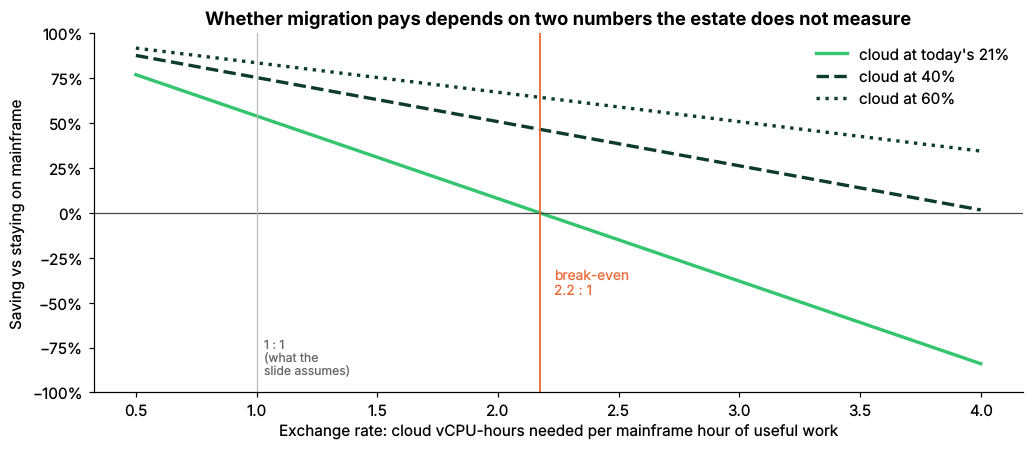

In [6]:
rates = np.linspace(0.5, 4.0, 71)
fig, ax = plt.subplots(figsize=(9.5, 4.2))
for util, ls, lab in [(unit.loc["cloud", "utilisation"], "-", f"cloud at today's {unit.loc['cloud','utilisation']:.0%}"),
                      (0.40, "--", "cloud at 40%"), (0.60, ":", "cloud at 60%")]:
    sav = 1 - np.array([target_cost("cloud", r, util) for r in rates]) / mf.cost_gbp
    ax.plot(rates, sav, ls, color=COL["cloud"] if ls == "-" else COL["mainframe"], lw=2.2, label=lab)
ax.axhline(0, color="#444", lw=0.8)
ax.axvline(1, color="#bbb", lw=0.8); ax.text(1.03, -0.9, "1 : 1\n(what the\nslide assumes)", fontsize=8, color="#666")
ax.axvline(breakeven["cloud"], color=ACCENT, lw=1.2)
ax.text(breakeven["cloud"] + 0.06, -0.45, f"break-even\n{breakeven['cloud']:.1f} : 1", color=ACCENT, fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_ylim(-1.0, 1.0)
ax.set_xlabel("Exchange rate: cloud vCPU-hours needed per mainframe hour of useful work")
ax.set_ylabel("Saving vs staying on mainframe")
ax.set_title("Whether migration pays depends on two numbers the estate does not measure")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout(); plt.savefig(OUT / "fig_exchange_rate.png", bbox_inches="tight"); plt.show()

**What to notice.** The migration case is not a property of the mainframe. It is a function of the
cloud estate's discipline (the three lines) and of an exchange rate nobody has measured (the x-axis).
Raise cloud utilisation and migration looks better; discover the workload needs 2–3 cloud cores per
mainframe core and it looks worse. **That is why "leave the mainframe?" is the wrong first question:**
the answer is decided by numbers that are fixable or measurable *before* anything moves.

## 4 · Money on the table without moving anything

Three levers, applied **in sequence** so no pound is counted twice:

1. **Idle** — workloads averaging under 5% utilisation all year: review and decommission.
2. **Right-size** — cloud and distributed workloads below a 60% utilisation target, shrunk to it.
   *Upper bound: storage does not shrink with compute.*
3. **Weekend off** — development and test on cloud and distributed switched off on Saturdays and
   Sundays, applied to what remains after right-sizing.

Pay-as-you-go platforms bank these savings straight away. On the **mainframe** the same idle
capacity is real, but turning it into cash needs a capacity or contract change — so it is reported
separately as *capacity to reclaim* rather than claimed as a saving.

In [7]:
IDLE_MAX, TARGET_UTIL = 5.0, 60.0
est["weekend_cost"] = est.cost_gbp.where(est.usage_date.dt.dayofweek >= 5, 0.0)
wl = (est.groupby(["workload_id", "business_unit", "platform", "environment", "service", "region"], as_index=False)
         .agg(cost_gbp=("cost_gbp", "sum"), util=("utilisation_pct", "mean"),
              useful_hrs=("useful_vcpu_hours", "sum"), billed_hrs=("vcpu_hours", "sum"),
              weekend_cost=("weekend_cost", "sum"),
              carbon_kg=("carbon_kg", "sum")))
payg = wl.platform.isin(["cloud", "distributed"])
nonprod = wl.environment.isin(["development", "test"])
wl["idle"] = wl.util < IDLE_MAX

wl["save_idle"] = np.where(payg & wl.idle, wl.cost_gbp, 0.0)
keep = np.where(payg & ~wl.idle & (wl.util < TARGET_UTIL), wl.util / TARGET_UTIL, 1.0)
wl["save_rightsize"] = np.where(payg & ~wl.idle, wl.cost_gbp * (1 - keep), 0.0)
wl["save_weekend"] = np.where(payg & ~wl.idle & nonprod, wl.weekend_cost * keep, 0.0)
wl["save_total"] = wl[["save_idle", "save_rightsize", "save_weekend"]].sum(axis=1)
wl["mf_capacity_to_reclaim"] = np.where((wl.platform == "mainframe") & wl.idle, wl.cost_gbp, 0.0)

lev = pd.Series({"Idle (cloud + distributed)": wl.save_idle.sum(),
                 "Right-size to 60%": wl.save_rightsize.sum(),
                 "Weekend off, non-prod": wl.save_weekend.sum()})
payg_spend = wl.loc[payg, "cost_gbp"].sum()
print(f"Cloud + distributed spend : {gbp(payg_spend)}")
for k, v in lev.items():
    print(f"  {k:<28}{gbp(v):>10}")
print(f"  {'Realisable now':<28}{gbp(lev.sum()):>10}  = {lev.sum()/payg_spend:.0%} of cloud+distributed spend, "
      f"{lev.sum()/TOTAL:.1%} of the estate")
print(f"\nMainframe capacity to reclaim (idle workloads): {gbp(wl.mf_capacity_to_reclaim.sum())} "
      f"across {int(((wl.platform=='mainframe') & wl.idle).sum())} workloads — needs a capacity/contract change to bank")

Cloud + distributed spend : £2.18M
  Idle (cloud + distributed)       £242k
  Right-size to 60%                £890k
  Weekend off, non-prod             £69k
  Realisable now                  £1.20M  = 55% of cloud+distributed spend, 7.8% of the estate

Mainframe capacity to reclaim (idle workloads): £1.19M across 39 workloads — needs a capacity/contract change to bank


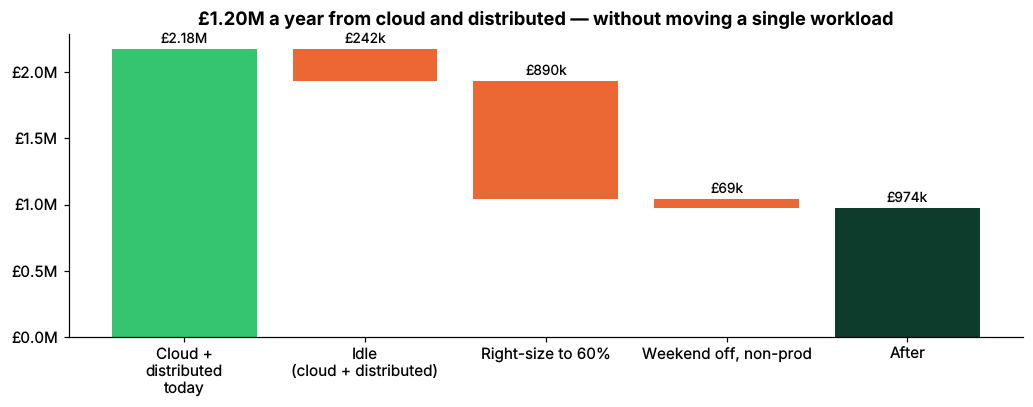

In [8]:
fig, ax = plt.subplots(figsize=(9.5, 3.8))
steps = [("Cloud +\ndistributed\ntoday", payg_spend)] + [(k.replace(" (", "\n("), -v) for k, v in lev.items()]
run = 0
for i, (lab, v) in enumerate(steps):
    bottom = run if v < 0 else 0
    run = run + v if i else v
    ax.bar(i, abs(v), bottom=run if v < 0 else 0, color=COL["cloud"] if i == 0 else ACCENT)
    ax.text(i, (run if v < 0 else 0) + abs(v) + payg_spend*0.02, gbp(abs(v)), ha="center", fontsize=9)
ax.bar(len(steps), run, color=COL["mainframe"]); ax.text(len(steps), run + payg_spend*0.02, gbp(run), ha="center", fontsize=9)
ax.set_xticks(range(len(steps) + 1), [s[0] for s in steps] + ["After"])
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"£{v/1e6:.1f}M"))
ax.set_title(f"{gbp(lev.sum())} a year from cloud and distributed — without moving a single workload")
plt.tight_layout(); plt.savefig(OUT / "fig_waterfall.png", bbox_inches="tight"); plt.show()

### The savings queue

Every lever lands on a named workload and a named owner, ranked by value — the thing an engineer can
actually pick up on Monday. Exported to `outputs/savings_queue.csv`.

In [9]:
queue = wl.loc[(wl.save_total > 0) | (wl.mf_capacity_to_reclaim > 0)].copy()
queue["action"] = np.select(
    [wl.loc[queue.index, "mf_capacity_to_reclaim"] > 0, queue.save_idle > 0, queue.save_weekend > 0],
    ["Mainframe: idle — reclaim capacity", "Decommission (idle all year)", "Right-size + weekend off"],
    default="Right-size to 60%")
queue["annual_value_gbp"] = queue.save_total + queue.mf_capacity_to_reclaim
queue["owner"] = queue.business_unit.where(queue.business_unit != "UNALLOCATED", "UNALLOCATED — find owner first")
queue = queue.sort_values("annual_value_gbp", ascending=False)
cols = ["workload_id", "owner", "platform", "environment", "service", "util", "cost_gbp", "action", "annual_value_gbp"]
queue[cols].round(2).to_csv(OUT / "savings_queue.csv", index=False)
print(f"{len(queue):,} actions; top 10 by value:")
queue[cols].head(10).style.format({"util": "{:.1f}%", "cost_gbp": "£{:,.0f}", "annual_value_gbp": "£{:,.0f}"}).hide(axis="index")

842 actions; top 10 by value:


workload_id,owner,platform,environment,service,util,cost_gbp,action,annual_value_gbp
WL-00088,Commercial Banking,mainframe,staging,VSAM Storage,2.7%,"£119,096",Mainframe: idle — reclaim capacity,"£119,096"
WL-00418,Collections,mainframe,staging,RACF Security,2.7%,"£103,310",Mainframe: idle — reclaim capacity,"£103,310"
WL-00848,Finance,mainframe,staging,z/OS Connect,2.7%,"£65,491",Mainframe: idle — reclaim capacity,"£65,491"
WL-00053,Mortgages,mainframe,test,CICS Transaction Server,2.7%,"£56,981",Mainframe: idle — reclaim capacity,"£56,981"
WL-00507,Fraud Operations,mainframe,staging,IMS Transaction Manager,2.7%,"£54,424",Mainframe: idle — reclaim capacity,"£54,424"
WL-00639,Customer Operations,mainframe,production,IMS Transaction Manager,2.8%,"£53,326",Mainframe: idle — reclaim capacity,"£53,326"
WL-00403,Fraud Operations,mainframe,development,Db2 for z/OS,2.7%,"£52,980",Mainframe: idle — reclaim capacity,"£52,980"
WL-00758,Internal Audit,mainframe,production,VSAM Storage,2.6%,"£47,908",Mainframe: idle — reclaim capacity,"£47,908"
WL-00433,Finance,mainframe,production,Tape Virtualisation,2.7%,"£43,601",Mainframe: idle — reclaim capacity,"£43,601"
WL-00190,Marketing,mainframe,test,IMS Transaction Manager,2.7%,"£41,050",Mainframe: idle — reclaim capacity,"£41,050"


## 5 · Nobody's money

Chargeback only changes behaviour if someone receives the bill. How much spend has no owner — and can
we work out who owns it from what we know about the workload?

UNALLOCATED: 69 workloads, £1.16M = 7.6% of spend — rank #1 of 25 'business units'
Largest real owner: Customer Operations £1.02M

Unallocated spend by platform:
platform
mainframe      7.8%
distributed    7.1%
cloud          4.9%


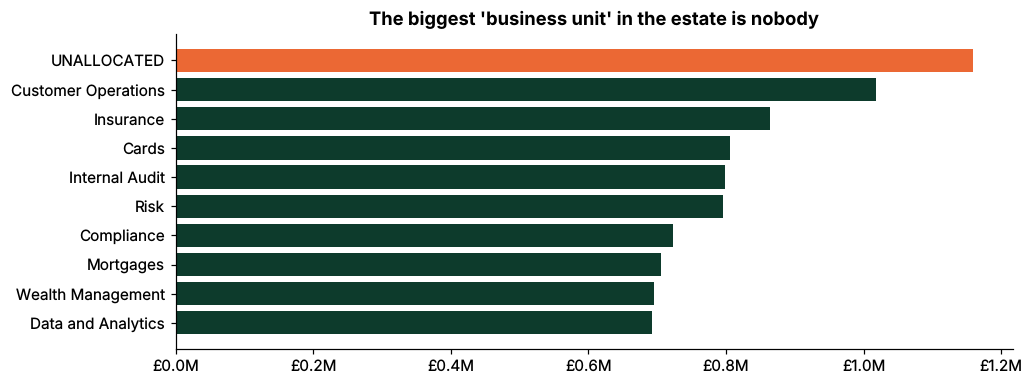

In [10]:
by_bu = wl.groupby("business_unit").cost_gbp.sum().sort_values(ascending=False)
un = wl[wl.business_unit == "UNALLOCATED"]
print(f"UNALLOCATED: {len(un)} workloads, {gbp(un.cost_gbp.sum())} = {un.cost_gbp.sum()/TOTAL:.1%} of spend "
      f"— rank #{list(by_bu.index).index('UNALLOCATED') + 1} of {len(by_bu)} 'business units'")
print("Largest real owner:", by_bu.drop("UNALLOCATED").index[0], gbp(by_bu.drop("UNALLOCATED").iloc[0]))
print("\nUnallocated spend by platform:")
print((un.groupby("platform").cost_gbp.sum() / wl.groupby("platform").cost_gbp.sum()).reindex(PLAT).map("{:.1%}".format).to_string())

fig, ax = plt.subplots(figsize=(9.5, 3.6))
top = by_bu.head(10)
ax.barh(top.index[::-1], top.values[::-1], color=[ACCENT if i == "UNALLOCATED" else COL["mainframe"] for i in top.index[::-1]])
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"£{v/1e6:.1f}M"))
ax.set_title("The biggest 'business unit' in the estate is nobody")
plt.tight_layout(); plt.savefig(OUT / "fig_unallocated.png", bbox_inches="tight"); plt.show()

### What we ruled out: inferring the owner

The tempting fix is a model that guesses each untagged workload's owner from its service, platform,
environment, region, size and utilisation. We trained one on the tagged workloads and cross-validated
it against two baselines.

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

tagged = wl[wl.business_unit != "UNALLOCATED"]
X = pd.get_dummies(tagged[["service", "platform", "environment", "region"]]).assign(
        log_cost=np.log(tagged.cost_gbp), util=tagged.util)
y = tagged.business_unit
cv = StratifiedKFold(5, shuffle=True, random_state=0)
rf = cross_val_score(RandomForestClassifier(300, random_state=0, n_jobs=-1), X, y, cv=cv).mean()
mode = cross_val_score(DummyClassifier(strategy="most_frequent"), X, y, cv=cv).mean()
print(f"random forest     : {rf:.1%} accuracy")
print(f"always-guess-mode : {mode:.1%}")
print(f"pure chance (1/{y.nunique()}): {1/y.nunique():.1%}")

random forest     : 4.3% accuracy
always-guess-mode : 5.9%
pure chance (1/24): 4.2%


**Result: no better than chance.** In this estate ownership carries no technical fingerprint, and we
would rather say so than ship a model that confidently assigns £1M+ of cost to the wrong team. The
fix is a **process, not a model**: *no tag, no deploy* at provisioning, and until then show the
unallocated line on the **platform owner's** bill, so it is somebody's problem every month.

## 6 · A fourth dimension: carbon per useful hour

> **Synthetic grid intensity.** Shape is realistic; values are not measurements. This shows the
> *method* — do not quote it as a finding about any real grid or platform.

The same unit works for energy and carbon: divide by useful hours, not billed ones.

In [12]:
cu = (est.groupby("platform").agg(kwh=("energy_kwh", "sum"), kg=("carbon_kg", "sum"),
                                  billed=("vcpu_hours", "sum"), useful=("useful_vcpu_hours", "sum")).reindex(PLAT))
cu["Wh_per_billed_hr"] = cu.kwh / cu.billed * 1000
cu["Wh_per_useful_hr"] = cu.kwh / cu.useful * 1000
cu["gCO2_per_useful_hr"] = cu.kg / cu.useful * 1000
idle_kg = wl.loc[wl.idle, "carbon_kg"].sum()
display(cu[["Wh_per_billed_hr", "Wh_per_useful_hr", "gCO2_per_useful_hr"]].round(2))
print(f"Carbon from workloads idle all year: {idle_kg/1000:,.1f} tCO2e ({idle_kg/est.carbon_kg.sum():.1%} of the estate) — "
      "emitted for no work at all")

,Wh_per_billed_hr,Wh_per_useful_hr,gCO2_per_useful_hr
platform,,,
mainframe,19.5,27.41,4.59
distributed,12.8,35.12,5.89
cloud,7.1,33.21,5.58


Carbon from workloads idle all year: 12.9 tCO2e (9.8% of the estate) — emitted for no work at all


Per billed hour the cloud looks greenest; per useful hour, in this synthetic estate, the busy
mainframe does a unit of work for the least energy. The point is not which platform wins — it is that
**the billed-hour view gets the ranking backwards** for carbon just as it does for cost.

## 7 · One picture per business unit

The boardroom view: every owner, every platform, one unit. Exported to `outputs/bu_scorecard.csv`.

In [13]:
mf_cost = wl[wl.platform == "mainframe"].groupby("business_unit").cost_gbp.sum()
sc = (wl.groupby("business_unit")
        .agg(workloads=("workload_id", "count"), spend_gbp=("cost_gbp", "sum"),
             useful_hrs=("useful_hrs", "sum"), billed_hrs=("billed_hrs", "sum"),
             save_now_gbp=("save_total", "sum"), mf_reclaim_gbp=("mf_capacity_to_reclaim", "sum"),
             carbon_t=("carbon_kg", lambda s: s.sum() / 1000)))
sc["mainframe_share"] = mf_cost.reindex(sc.index).fillna(0) / sc.spend_gbp
sc["utilisation"] = sc.useful_hrs / sc.billed_hrs
sc["gbp_per_useful_hr"] = sc.spend_gbp / sc.useful_hrs
sc = sc.drop(columns=["useful_hrs", "billed_hrs"]).sort_values("spend_gbp", ascending=False)
sc.round(4).to_csv(OUT / "bu_scorecard.csv")
sc.head(12).style.format({"spend_gbp": "£{:,.0f}", "save_now_gbp": "£{:,.0f}", "mf_reclaim_gbp": "£{:,.0f}",
                          "carbon_t": "{:,.1f} t", "mainframe_share": "{:.0%}", "utilisation": "{:.0%}",
                          "gbp_per_useful_hr": "£{:.3f}"})

,workloads,spend_gbp,save_now_gbp,mf_reclaim_gbp,carbon_t,mainframe_share,utilisation,gbp_per_useful_hr
business_unit,,,,,,,,
UNALLOCATED,69,"£1,159,419","£63,861","£64,216",9.6 t,89%,56%,£0.565
Customer Operations,64,"£1,018,088","£64,014","£74,477",8.1 t,90%,52%,£0.618
Insurance,53,"£863,537","£87,432","£48,251",7.4 t,83%,45%,£0.561
Cards,38,"£806,437","£27,699","£22,270",6.0 t,94%,61%,£0.606
Internal Audit,49,"£799,010","£39,500","£47,908",6.3 t,91%,56%,£0.588
Risk,51,"£795,645","£45,694","£12,459",6.5 t,89%,56%,£0.564
Compliance,45,"£723,175","£32,808","£30,147",5.8 t,91%,59%,£0.578
Mortgages,40,"£705,825","£41,144","£56,981",6.0 t,87%,53%,£0.566
Wealth Management,51,"£696,006","£49,797","£57,135",6.2 t,84%,50%,£0.546


## 8 · Three numbers for the boardroom

Exported to `outputs/deck_numbers.json` so the presentation quotes exactly what this notebook computed.

In [14]:
nums = {
    "total_spend_gbp": TOTAL,
    "workloads": int(wl.shape[0]),
    "platform": {p: {"spend_gbp": unit.loc[p, "cost_gbp"], "share": unit.loc[p, "share_of_spend"],
                     "utilisation": unit.loc[p, "utilisation"], "gbp_per_billed": unit.loc[p, "gbp_per_billed"],
                     "gbp_per_useful": unit.loc[p, "gbp_per_useful"],
                     "wh_per_billed": cu.loc[p, "Wh_per_billed_hr"], "wh_per_useful": cu.loc[p, "Wh_per_useful_hr"],
                     "g_per_useful": cu.loc[p, "gCO2_per_useful_hr"]} for p in PLAT},
    "gap_billed": unit.loc["mainframe", "billed_vs_cloud"],
    "gap_useful": unit.loc["mainframe", "useful_vs_cloud"],
    "mainframe_spend_gbp": mf.cost_gbp,
    "naive_saving": 1 - naive_cloud / mf.cost_gbp,
    "aware_saving": 1 - aware_cloud / mf.cost_gbp,
    "breakeven_cloud": breakeven["cloud"], "breakeven_distributed": breakeven["distributed"],
    "exchange_curve": {lab: [[float(r), float(1 - target_cost("cloud", r, u) / mf.cost_gbp)] for r in np.arange(0.5, 4.01, 0.5)]
                       for lab, u in [("today", unit.loc["cloud", "utilisation"]), ("40%", 0.40), ("60%", 0.60)]},
    "levers": lev.to_dict(), "save_now_gbp": lev.sum(), "payg_spend_gbp": payg_spend,
    "mf_reclaim_gbp": wl.mf_capacity_to_reclaim.sum(), "mf_idle_workloads": int(((wl.platform == "mainframe") & wl.idle).sum()),
    "idle_workloads": int(wl.idle.sum()),
    "unallocated_gbp": un.cost_gbp.sum(), "unallocated_share": un.cost_gbp.sum() / TOTAL,
    "unallocated_workloads": int(len(un)), "unallocated_rank": list(by_bu.index).index("UNALLOCATED") + 1,
    "top_bus": [[k, float(v)] for k, v in by_bu.head(8).items()],
    "owner_model_acc": rf, "owner_mode_acc": mode, "owner_chance": 1 / y.nunique(),
    "idle_carbon_t": idle_kg / 1000, "idle_carbon_share": idle_kg / est.carbon_kg.sum(),
    "recon_diff_gbp": abs(recon), "rows": int(len(est)),
}
(OUT / "deck_numbers.json").write_text(json.dumps(nums, indent=2, default=float))

print(f"1. A useful hour on the mainframe costs {nums['gap_useful']:.1f}× cloud — not the {nums['gap_billed']:.1f}× the bill suggests.")
print(f"2. {gbp(nums['save_now_gbp'])} a year is available now, without migrating anything "
      f"(+ {gbp(nums['mf_reclaim_gbp'])} of idle mainframe capacity to reclaim).")
print(f"3. {gbp(nums['unallocated_gbp'])} ({nums['unallocated_share']:.1%}) has no owner — the largest 'business unit' in the estate.")

1. A useful hour on the mainframe costs 2.2× cloud — not the 7.2× the bill suggests.
2. £1.20M a year is available now, without migrating anything (+ £1.19M of idle mainframe capacity to reclaim).
3. £1.16M (7.6%) has no owner — the largest 'business unit' in the estate.


## 9 · Limits, and what we would do next

**What this is.** A proof of concept on synthetic data (≈ TRL 3): the unit, the exchange-rate test,
the savings queue and the scorecard all run end-to-end on the challenge lake and reconcile to source.

**Where it breaks first**

- *Utilisation means different things on different platforms.* Mainframe utilisation of a shared LPAR
  is not the same measurement as a cloud VM's CPU average. A production version needs an agreed
  definition per platform — the single biggest risk to the unit.
- *The exchange rate is unmeasured.* We show what it must be for migration to pay; a real estate
  should benchmark a handful of representative workloads to pin it down.
- *Cost here is linear in usage.* Real mainframe software is often priced on peak capacity (e.g. a
  rolling four-hour average), so the month-end batch peaks in this data (up to ~4× a normal day) would
  matter far more in a real bill — smoothing them is the next lever we would model.
- *Right-sizing is an upper bound* — storage and licences do not shrink with vCPUs.

**What we ruled out.** Inferring owners with ML (chance-level, section 5); quoting carbon as a real
finding (synthetic intensity, section 6).

**Next.** Add the useful-hour unit as a standard measure in the sponsor's viewer; feed the savings
queue into the ticketing tool; publish the BU scorecard monthly alongside chargeback.